# SVM RBF — Student Dropout
Người thực hiện: **Trần Minh Triết**. Dùng development.csv; chưa đánh giá test.

Thử ranh giới phi tuyến; chuẩn hóa biến định lượng.

Chạy từng cell từ trên xuống. Đóng Excel trước khi chạy. Dùng học kỳ 2 nên không gọi đây là dự đoán lúc nhập học.

## 1. Đọc dữ liệu và cố định thực nghiệm

### Thông tin thực nghiệm và thư viện

In [2]:
OWNER = 'Trần Minh Triết'
OWNER_ID = 'triet'
MODEL_NAME = 'SVM RBF'
SCALE_NUMERIC = True
from pathlib import Path
from datetime import datetime
import hashlib, json, platform, uuid, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
try:
    from IPython.display import display
except ImportError:
    display = print
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, recall_score, classification_report, ConfusionMatrixDisplay



### Đọc và kiểm tra dữ liệu development

In [3]:
project_dir = Path.cwd().resolve()
if project_dir.name == 'notebooks':
    project_dir = project_dir.parent
data_path = project_dir / 'data' / 'processed' / 'development.csv'
if not data_path.exists():
    raise FileNotFoundError(f'Không tìm thấy {data_path}. Chạy bước chia dữ liệu trong 01_eda.ipynb trước.')
data = pd.read_csv(data_path)
data.columns = [' '.join(c.split()) for c in data.columns]
assert not data.columns.duplicated().any()
assert data.isna().sum().sum() == 0, 'Phát hiện missing: cần kiểm tra lại.'
X = data.drop(columns='Target')
label_names = ['Dropout', 'Enrolled', 'Graduate']
label_mapping = {label: i for i, label in enumerate(label_names)}
assert set(data['Target'].unique()) == set(label_names)
y = data['Target'].map(label_mapping).astype(int)
print('Mã nhãn:', label_mapping)


Mã nhãn: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}


### Thiết lập cross-validation và metrics

In [4]:
DATA_HASH = hashlib.sha256(data_path.read_bytes()).hexdigest()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(cv.split(X, y))
scoring = {
    'accuracy': 'accuracy', 'macro_f1': 'f1_macro', 'weighted_f1': 'f1_weighted',
    'recall_dropout': make_scorer(recall_score, labels=[0], average='macro', zero_division=0)
}


### Tạo thư mục lưu kết quả

In [5]:
experiment_dir = project_dir / 'experiments' / OWNER_ID
figure_dir = project_dir / 'report' / 'figures' / OWNER_ID
model_dir = project_dir / 'models' / OWNER_ID
for directory in [experiment_dir, figure_dir, model_dir]:
    directory.mkdir(parents=True, exist_ok=True)
print('Người thực hiện:', OWNER)
print('X:', X.shape, '| y:', y.shape)
print('SHA256 dữ liệu:', DATA_HASH)
print('Không đọc test.csv. CV chỉ chạy trên development.csv.')


Người thực hiện: Trần Minh Triết
X: (3539, 36) | y: (3539,)
SHA256 dữ liệu: dfe524288135ecf474ab9b9cf03277f19b818b879cafc176a571aa2a9dbaa690
Không đọc test.csv. CV chỉ chạy trên development.csv.


## 2. Xây dựng tiền xử lý

### Phân nhóm đặc trưng và kiểm tra

In [6]:
categorical_cols = ['Marital status', 'Application mode', 'Course', 'Previous qualification',
    'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
binary_cols = ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor',
    'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
numeric_cols = ['Application order', 'Previous qualification (grade)', 'Admission grade',
    'Age at enrollment', 'Unemployment rate', 'Inflation rate', 'GDP'] + [
    f'Curricular units {semester} sem ({measure})'
    for semester in ['1st', '2nd'] for measure in [
        'credited', 'enrolled', 'evaluations', 'approved', 'grade', 'without evaluations']]
assigned = categorical_cols + binary_cols + numeric_cols
assert len(assigned) == len(set(assigned)) == 36
assert set(assigned) == set(X.columns)
for col in binary_cols:
    assert set(X[col].unique()) <= {0, 1}, col


### Hàm xây dựng pipeline tiền xử lý

In [7]:
def build_pipeline(estimator):
    processor = ColumnTransformer([
        ('category', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('numeric', StandardScaler() if SCALE_NUMERIC else 'passthrough', numeric_cols),
        ('binary', 'passthrough', binary_cols)
    ])
    return Pipeline([('preprocessing', processor), ('model', estimator)])

print('Đủ 36 đặc trưng. Pipeline sẽ fit tiền xử lý riêng trong từng fold.')


Đủ 36 đặc trưng. Pipeline sẽ fit tiền xử lý riêng trong từng fold.


## 3. Hàm đánh giá và nhật ký Excel

### Hàm ghi nhật ký Excel

In [8]:
log_path = experiment_dir / 'experiment_history.xlsx'

def save_log(row):
    # Đóng Excel trước khi chạy để tránh PermissionError trên Windows.
    frame = pd.DataFrame([row])
    if log_path.exists():
        old = pd.read_excel(log_path, sheet_name='Runs')
        frame = pd.concat([old, frame], ignore_index=True)
    frame.to_excel(log_path, sheet_name='Runs', index=False, engine='openpyxl')
    print('Đã ghi Excel:', log_path)


### Hàm đánh giá cross-validation

In [9]:
results = []
def run_cv(estimator, name, note):
    run_id = datetime.now().strftime('%Y%m%d_%H%M%S') + '_' + uuid.uuid4().hex[:6]
    scores = cross_validate(estimator, X, y, cv=folds, scoring=scoring,
        return_train_score=True, n_jobs=1, error_score='raise')
    details = pd.DataFrame({k: v for k, v in scores.items()})
    details.insert(0, 'fold', range(1, 6))
    details.to_csv(experiment_dir / f'{run_id}_folds.csv', index=False)
    row = {
        'Run_ID': run_id, 'Timestamp': datetime.now().isoformat(timespec='seconds'),
        'Run_By': OWNER, 'Model': name, 'Stage': 'CV fixed configuration',
        'Data_SHA256': DATA_HASH, 'Samples': len(y),
        'Split': 'development 80%; StratifiedKFold 5; shuffle=True; seed=42',
        'Parameters': json.dumps(estimator.get_params(deep=False), default=str, ensure_ascii=False),
        'Preprocessing': 'OneHot categorical; binary passthrough; numeric ' + ('StandardScaler' if SCALE_NUMERIC else 'passthrough'),
        'Train_Macro_F1': scores['train_macro_f1'].mean(),
        'CV_Macro_F1': scores['test_macro_f1'].mean(),
        'CV_Macro_F1_STD': scores['test_macro_f1'].std(ddof=1),
        'CV_Accuracy': scores['test_accuracy'].mean(),
        'CV_Weighted_F1': scores['test_weighted_f1'].mean(),
        'CV_Recall_Dropout': scores['test_recall_dropout'].mean(),
        'Mean_Fit_Seconds': scores['fit_time'].mean(),
        'Python': platform.python_version(), 'sklearn': sklearn.__version__,
        'Note': note
    }
    save_log(row)
    results.append(row)
    display(pd.DataFrame([row])[['Model', 'Train_Macro_F1', 'CV_Macro_F1', 'CV_Macro_F1_STD', 'CV_Accuracy', 'CV_Recall_Dropout']])
    return scores


## 4. Baseline Dummy

In [10]:
dummy_scores = run_cv(DummyClassifier(strategy='most_frequent'), 'Dummy most frequent', 'Baseline; ignores input features.')

Đã ghi Excel: D:\sgu-MAYHOC\ML01_Student_Dropout\experiments\triet\experiment_history.xlsx


,Model,Train_Macro_F1,CV_Macro_F1,CV_Macro_F1_STD,CV_Accuracy,CV_Recall_Dropout
0,Dummy most frequent,0.222013,0.222013,0.000209,0.499294,0.0


## 5. Mô hình ban đầu

### Khởi tạo SVM RBF và không gian tham số

In [11]:
from sklearn.svm import SVC
model = SVC(kernel="rbf", C=1.0, gamma="scale")
param_grid = {"model__C": [0.1, 1.0, 10.0], "model__gamma": ["scale", 0.01], "model__class_weight": [None, "balanced"]}


### Đánh giá cấu hình ban đầu

In [12]:
initial_scores = run_cv(build_pipeline(model), MODEL_NAME + ' initial', 'Fixed initial configuration before tuning.')

Đã ghi Excel: D:\sgu-MAYHOC\ML01_Student_Dropout\experiments\triet\experiment_history.xlsx


,Model,Train_Macro_F1,CV_Macro_F1,CV_Macro_F1_STD,CV_Accuracy,CV_Recall_Dropout
0,SVM RBF initial,0.790752,0.685798,0.025249,0.76971,0.749301


### Nhận xét
     Điền số liệu thực tế sau khi chạy.
     So sánh với Dummy, xem chênh lệch train/CV và các lớp dễ nhầm.
     Điểm tuning là điểm lựa chọn; chưa phải đánh giá test độc lập.

## 6. Tinh chỉnh siêu tham số

### Chạy GridSearchCV và xuất bảng kết quả

In [13]:
search = GridSearchCV(build_pipeline(model), param_grid=param_grid,
    scoring='f1_macro', cv=folds, refit=True, n_jobs=1,
    return_train_score=True, error_score='raise')
started = time.perf_counter()
search.fit(X, y)
elapsed = time.perf_counter() - started
search_id = datetime.now().strftime('%Y%m%d_%H%M%S') + '_' + uuid.uuid4().hex[:6]
search_table = pd.DataFrame(search.cv_results_)
search_table.to_csv(experiment_dir / f'{search_id}_grid_search.csv', index=False)


### Ghi từng cấu hình tuning vào nhật ký Excel

In [14]:
# Ghi mọi cấu hình đã thử, không chỉ cấu hình thắng.
existing = pd.read_excel(log_path, sheet_name='Runs') if log_path.exists() else pd.DataFrame()
tuning_rows = []
for i, params in enumerate(search.cv_results_['params']):
    tuning_rows.append({
        'Run_ID': f'{search_id}_candidate_{i+1}',
        'Timestamp': datetime.now().isoformat(timespec='seconds'), 'Run_By': OWNER,
        'Model': MODEL_NAME, 'Stage': 'GridSearchCV candidate',
        'Data_SHA256': DATA_HASH, 'Samples': len(y),
        'Split': 'Same development; same 5 folds; seed=42',
        'Parameters': json.dumps(params, ensure_ascii=False),
        'Preprocessing': 'OneHot; binary passthrough; numeric ' + ('StandardScaler' if SCALE_NUMERIC else 'passthrough'),
        'Train_Macro_F1': search.cv_results_['mean_train_score'][i],
        'CV_Macro_F1': search.cv_results_['mean_test_score'][i],
        'CV_Macro_F1_STD': search.cv_results_['std_test_score'][i],
        'Mean_Fit_Seconds': search.cv_results_['mean_fit_time'][i],
        'Python': platform.python_version(), 'sklearn': sklearn.__version__,
        'Note': 'Điểm dùng chọn tham số; không phải đánh giá test độc lập.'
    })
pd.concat([existing, pd.DataFrame(tuning_rows)], ignore_index=True).to_excel(
    log_path, sheet_name='Runs', index=False, engine='openpyxl')


### Hiển thị kết quả tuning

In [15]:
print('Tham số tốt nhất:', search.best_params_)
print('CV Macro-F1 tốt nhất (điểm lựa chọn):', round(search.best_score_, 4))
print('Số cấu hình:', len(tuning_rows), '| Thời gian:', round(elapsed, 2), 'giây')
print('Đã lưu mọi cấu hình vào Excel:', log_path)
display(search_table[['params', 'mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']].sort_values('rank_test_score'))

print('Lưu ý: best_score_ là điểm chọn tham số, không phải điểm test độc lập.')


Tham số tốt nhất: {'model__C': 10.0, 'model__class_weight': 'balanced', 'model__gamma': 0.01}
CV Macro-F1 tốt nhất (điểm lựa chọn): 0.7154
Số cấu hình: 12 | Thời gian: 70.36 giây
Đã lưu mọi cấu hình vào Excel: D:\sgu-MAYHOC\ML01_Student_Dropout\experiments\triet\experiment_history.xlsx


,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
11,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.848826,0.715364,0.010171,1
6,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.818543,0.713370,0.016813,2
9,"{'model__C': 10.0, 'model__class_weight': None...",0.832752,0.705381,0.019241,3
7,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.736255,0.700852,0.012533,4
10,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.972217,0.695060,0.008582,5
8,"{'model__C': 10.0, 'model__class_weight': None...",0.967821,0.690690,0.015637,6
4,"{'model__C': 1.0, 'model__class_weight': None,...",0.790752,0.685798,0.022584,7
5,"{'model__C': 1.0, 'model__class_weight': None,...",0.720154,0.678851,0.015696,8
2,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.675039,0.654300,0.014900,9
3,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.651809,0.642608,0.012620,10


Lưu ý: best_score_ là điểm chọn tham số, không phải điểm test độc lập.


## 7. Phân tích lỗi và so sánh baseline

### Dự đoán out-of-fold và báo cáo phân loại

In [16]:
# OOF cho cấu hình ban đầu, chưa được chọn bằng tuning.
# Mỗi mẫu được dự đoán bởi mô hình không fit trên mẫu đó.
oof_pred = cross_val_predict(build_pipeline(model), X, y, cv=folds, n_jobs=1)
labels = [0, 1, 2]
report = classification_report(y, oof_pred, labels=labels, target_names=label_names, output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.round(4))
pd.DataFrame(report).T.to_csv(experiment_dir / 'initial_model_oof_report.csv', encoding='utf-8-sig')


,precision,recall,f1-score,support
Dropout,0.8264,0.7493,0.7860,1137.0000
Enrolled,0.5726,0.3354,0.4230,635.0000
Graduate,0.7767,0.9389,0.8501,1767.0000
accuracy,0.7697,0.7697,0.7697,0.7697
macro avg,0.7252,0.6746,0.6864,3539.0000
weighted avg,0.7560,0.7697,0.7529,3539.0000


### Vẽ ma trận nhầm lẫn

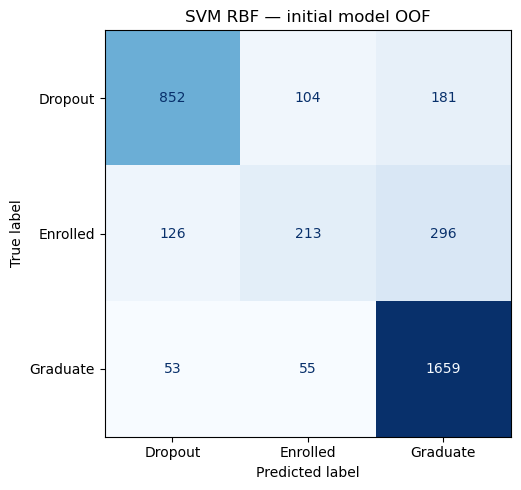

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y, oof_pred, labels=labels, display_labels=label_names, ax=ax, cmap='Blues', colorbar=False)
ax.set_title(MODEL_NAME + ' — initial model OOF')
fig.tight_layout()
fig.savefig(figure_dir / 'initial_model_oof_confusion.png', dpi=200)
plt.show()
plt.close(fig)


### So sánh với baseline

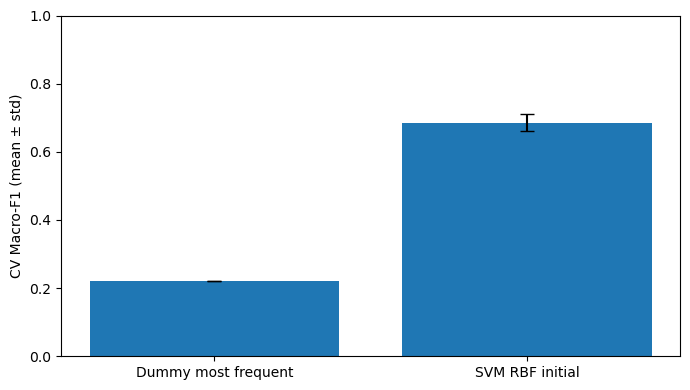

In [18]:
comparison = pd.DataFrame(results).set_index('Model')
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(comparison.index, comparison['CV_Macro_F1'], yerr=comparison['CV_Macro_F1_STD'], capsize=5)
ax.set_ylim(0, 1)
ax.set_ylabel('CV Macro-F1 (mean ± std)')
fig.tight_layout()
fig.savefig(figure_dir / 'baseline_comparison.png', dpi=200)
plt.show()
plt.close(fig)


### Nhận xét
     Điền số liệu thực tế sau khi chạy.
     So sánh với Dummy, xem chênh lệch train/CV và các lớp dễ nhầm.
     Điểm tuning là điểm lựa chọn; chưa phải đánh giá test độc lập.

## 8. Lưu pipeline ứng viên

### Lưu pipeline ứng viên

In [19]:
import joblib
# GridSearchCV đã refit cấu hình tốt nhất trên toàn bộ development.
# Đây là mô hình ứng viên; chưa xác nhận chất lượng trên test.
model_path = model_dir / 'candidate_pipeline.joblib'
joblib.dump(search.best_estimator_, model_path)


['D:\\sgu-MAYHOC\\ML01_Student_Dropout\\models\\triet\\candidate_pipeline.joblib']

### Lưu metadata và thông báo kết quả

In [20]:
metadata = {
    'owner': OWNER, 'model': MODEL_NAME, 'data_sha256': DATA_HASH,
    'best_params': search.best_params_, 'selection_cv_macro_f1': search.best_score_,
    'test_evaluated': False, 'sklearn': sklearn.__version__,
    'label_mapping': label_mapping, 'feature_columns': X.columns.tolist()
}
(model_dir / 'metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã lưu pipeline ứng viên:', model_path)
print('Nhật ký Excel:', log_path)
print('Chưa đánh giá test. Nhóm chọn mô hình bằng CV trước.')


Đã lưu pipeline ứng viên: D:\sgu-MAYHOC\ML01_Student_Dropout\models\triet\candidate_pipeline.joblib
Nhật ký Excel: D:\sgu-MAYHOC\ML01_Student_Dropout\experiments\triet\experiment_history.xlsx
Chưa đánh giá test. Nhóm chọn mô hình bằng CV trước.


### 9. Nhật ký tiến độ cá nhân



| Ngày | Công việc | Kết quả | Khó khăn | Bước tiếp theo |
|---|---|---|---|---|
| 05/11/2026 | Xây dựng mô hình SVM RBF và thiết lập tiền xử lý dữ liệu | Xây dựng Pipeline gồm OneHotEncoder, StandardScaler và SVC; thiết lập 5-fold Cross-Validation | SVM cần chuẩn hóa dữ liệu số và thời gian huấn luyện có thể kéo dài | Đánh giá mô hình ban đầu và so sánh với Dummy |
| 05/11/2026 | Thiết lập đánh giá SVM ban đầu và tinh chỉnh bằng GridSearchCV | Xây dựng các cấu hình thử nghiệm với tham số C, gamma và class_weight; sử dụng Macro-F1 để lựa chọn mô hình | Việc thử nhiều cấu hình bằng Cross-Validation tốn thời gian | Chạy thực nghiệm, ghi nhận kết quả và chọn tham số tốt nhất |
| 05/11/2026 | Xây dựng phần phân tích lỗi và lưu mô hình ứng viên | Bổ sung đánh giá OOF, ma trận nhầm lẫn, biểu đồ so sánh baseline và chức năng lưu Pipeline | Cần xem xét khả năng phân loại của từng lớp, đặc biệt là Enrolled | Phân tích kết quả thực tế và so sánh SVM với các mô hình khác |
